In [1]:
import time
import pandas as pd
from functools import reduce
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.appName("05_performance").getOrCreate()
spark.conf.set("spark.sql.session.timeZone", "UTC")

PROJECT = "grandes-datos-506301"
BUCKET = "taxis-chicago-grandes-datos-506301"
BRONZE_TAXI = f"gs://{BUCKET}/bronze/taxi_trips"
SILVER_TAXI = f"gs://{BUCKET}/silver/taxi_trips"
GOLD = f"gs://{BUCKET}/gold"
RESULTS = f"gs://{BUCKET}/performance"

results = []   # aquí se acumulan todos los tiempos


def timed(label, action):
    """Corre una acción de Spark, mide cuánto tarda y lo guarda."""
    start = time.perf_counter()
    out = action()
    seconds = round(time.perf_counter() - start, 1)
    results.append({"test": label, "seconds": seconds})
    print(f"{label}: {seconds} s")
    return out

26/10/08 17:41:27 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [2]:
bronze = spark.read.parquet(BRONZE_TAXI)
silver = spark.read.parquet(SILVER_TAXI)
gold = spark.read.parquet(f"{GOLD}/zone_hour_demand")

rows = {"bronze": timed("rows bronze", bronze.count),
        "silver": timed("rows silver", silver.count),
        "gold": timed("rows gold", gold.count)}
rows

rows bronze: 50.3 s


rows silver: 12.9 s


rows gold: 2.2 s


{'bronze': 212046737, 'silver': 142333309, 'gold': 7371672}

In [3]:
def trips_per_year(df):
    return (df.groupBy(F.year("trip_start_timestamp").alias("year"))
            .count().orderBy("year").toPandas())


by_year_parquet = timed("exp1 bronze parquet", lambda: trips_per_year(bronze))

bq = (spark.read.format("bigquery")
      .option("parentProject", PROJECT)
      .load("bigquery-public-data.chicago_taxi_trips.taxi_trips")
      .filter("trip_start_timestamp < '2024-01-01'"))   # mismo periodo que bronze
by_year_bq = timed("exp1 bigquery", lambda: trips_per_year(bq))

by_year_parquet

exp1 bronze parquet: 58.8 s


exp1 bigquery: 42.4 s


,year,count
0,2013,35438190
1,2014,39523076
2,2015,23604750
3,2016,22707263
4,2017,19582632
5,2018,19206406
6,2019,24994550
7,2020,5894649
8,2021,7767266
9,2022,6793419


In [4]:
pruned = silver.filter("year = 2023")
not_pruned = silver.filter("trip_date >= '2023-01-01'")

pruned.explain()        # busca: PartitionFilters: [isnotnull(year...), (year = 2023)]
not_pruned.explain()    # aquí PartitionFilters sale vacío: []

for run in (1, 2):      # dos vueltas: la primera calienta el clúster
    timed(f"exp2 partition filter, run {run}", pruned.count)
    timed(f"exp2 no partition filter, run {run}", not_pruned.count)

== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [unique_key#46,taxi_id#47,trip_start_timestamp#48,trip_end_timestamp#49,trip_seconds#50,trip_miles#51,pickup_community_area#52,dropoff_community_area#53,fare#54,tips#55,tolls#56,extras#57,trip_total#58,payment_type#59,company#60,pickup_latitude#61,pickup_longitude#62,trip_date#63,trip_hour#64,year#65,month#66] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[gs://taxis-chicago-grandes-datos-506301/silver/taxi_trips], PartitionFilters: [isnotnull(year#65), (year#65 = 2023)], PushedFilters: [], ReadSchema: struct<unique_key:string,taxi_id:string,trip_start_timestamp:timestamp,trip_end_timestamp:timesta...


== Physical Plan ==
*(1) Filter (isnotnull(trip_date#63) AND (trip_date#63 >= 2023-01-01))
+- *(1) ColumnarToRow
   +- FileScan parquet [unique_key#46,taxi_id#47,trip_start_timestamp#48,trip_end_timestamp#49,trip_seconds#50,trip_miles#51,pickup_community_area#52,dropoff_community_area#53,fa

exp2 partition filter, run 1: 2.5 s


exp2 no partition filter, run 1: 14.3 s


exp2 partition filter, run 2: 1.3 s


exp2 no partition filter, run 2: 7.0 s


In [5]:
RULES = {
    "missing_start_time":  F.col("trip_start_timestamp").isNull(),
    "missing_pickup_area": F.col("pickup_community_area").isNull(),
    "invalid_duration":    F.col("trip_seconds").isNull() | ~F.col("trip_seconds").between(60, 4 * 3600),
    "invalid_fare":        F.col("fare").isNull() | (F.col("fare") <= 0) | (F.col("fare") > 500),
    "end_before_start":    F.col("trip_end_timestamp") < F.col("trip_start_timestamp"),
}


def clean(df):
    df = df.select(
        "unique_key", "taxi_id", "trip_start_timestamp", "trip_end_timestamp",
        F.col("trip_seconds").cast("int").alias("trip_seconds"),
        F.col("trip_miles").cast("double").alias("trip_miles"),
        F.col("pickup_community_area").cast("int").alias("pickup_community_area"),
        F.col("dropoff_community_area").cast("int").alias("dropoff_community_area"),
        F.col("fare").cast("double").alias("fare"),
        F.col("tips").cast("double").alias("tips"),
        F.col("tolls").cast("double").alias("tolls"),
        F.col("extras").cast("double").alias("extras"),
        F.col("trip_total").cast("double").alias("trip_total"),
        F.initcap(F.trim("payment_type")).alias("payment_type"),
        F.trim("company").alias("company"),
        F.col("pickup_latitude").cast("double").alias("pickup_latitude"),
        F.col("pickup_longitude").cast("double").alias("pickup_longitude"))
    rejected = reduce(lambda a, b: a | b, [F.coalesce(c, F.lit(False)) for c in RULES.values()])
    return (df.dropDuplicates(["unique_key"])
            .filter(~rejected)
            .na.fill({"tips": 0.0, "tolls": 0.0, "extras": 0.0,
                      "company": "Unknown", "payment_type": "Unknown"})
            .withColumn("trip_date", F.to_date("trip_start_timestamp"))
            .withColumn("year", F.year("trip_start_timestamp")))


scaling = []
for first_year in (2023, 2021, 2018, 2013):          # 1, 3, 6 y 11 años
    years = 2024 - first_year
    subset = bronze.filter(F.year("trip_start_timestamp").between(first_year, 2023))
    n_rows = int(by_year_parquet.query("@first_year <= year <= 2023")["count"].sum())
    timed(f"exp3 silver {years} years",
          lambda: clean(subset).write.format("noop").mode("overwrite").save())
    scaling.append({"years": years, "rows": n_rows, "seconds": results[-1]["seconds"]})

scaling_pd = pd.DataFrame(scaling)
scaling_pd["seconds_per_million_rows"] = (scaling_pd["seconds"] / scaling_pd["rows"] * 1e6).round(2)
scaling_pd

26/10/08 17:45:05 WARN package: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


exp3 silver 1 years: 146.9 s


exp3 silver 3 years: 219.0 s


exp3 silver 6 years: 466.7 s


exp3 silver 11 years: 2091.5 s


,years,rows,seconds,seconds_per_million_rows
0,1,6534536,146.9,22.48
1,3,21095221,219.0,10.38
2,6,71190826,466.7,6.56
3,11,212046737,2091.5,9.86


In [7]:
spark.createDataFrame(pd.DataFrame(results)).coalesce(1).write.mode("overwrite") \
    .option("header", True).csv(f"{RESULTS}/timings")
spark.createDataFrame(scaling_pd).coalesce(1).write.mode("overwrite") \
    .option("header", True).csv(f"{RESULTS}/scaling")
pd.DataFrame(results)

,test,seconds
0,rows bronze,50.3
1,rows silver,12.9
2,rows gold,2.2
3,exp1 bronze parquet,58.8
4,exp1 bigquery,42.4
5,"exp2 partition filter, run 1",2.5
6,"exp2 no partition filter, run 1",14.3
7,"exp2 partition filter, run 2",1.3
8,"exp2 no partition filter, run 2",7.0
9,exp3 silver 1 years,146.9


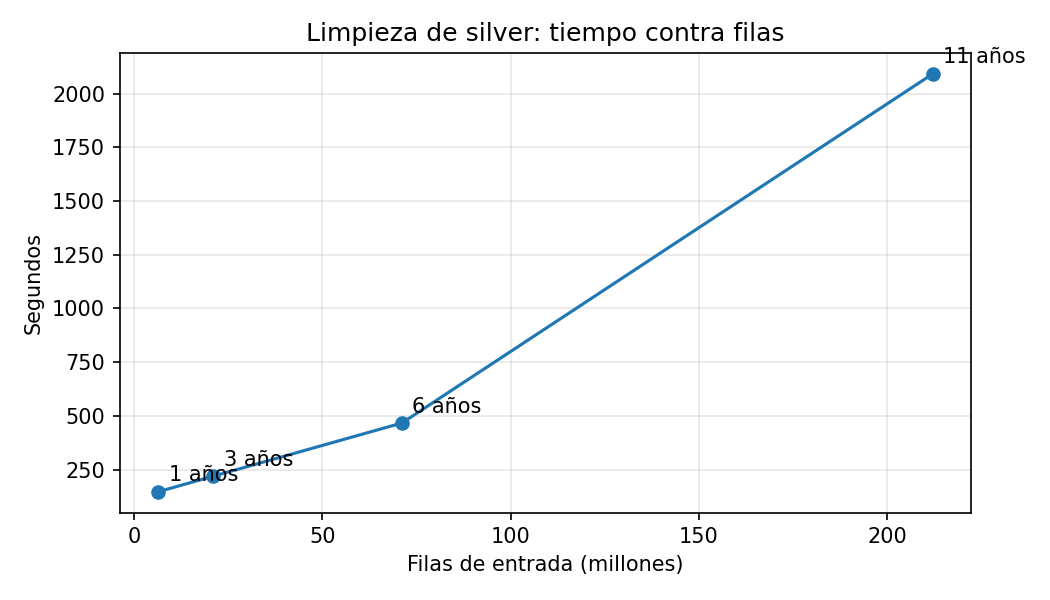

CompletedProcess(args='gsutil -q cp /tmp/scaling.png gs://taxis-chicago-grandes-datos-506301/performance/scaling.png', returncode=0)

In [8]:
import subprocess
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display

plt.switch_backend("Agg")   # dibuja a archivo, sin el paquete que falla

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(scaling_pd["rows"] / 1e6, scaling_pd["seconds"], marker="o")
for _, r in scaling_pd.iterrows():
    ax.annotate(f"{int(r['years'])} años", (r["rows"] / 1e6, r["seconds"]),
                textcoords="offset points", xytext=(5, 5))
ax.set_title("Limpieza de silver: tiempo contra filas")
ax.set_xlabel("Filas de entrada (millones)")
ax.set_ylabel("Segundos")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig("/tmp/scaling.png", dpi=150)

display(Image("/tmp/scaling.png"))
subprocess.run(f"gsutil -q cp /tmp/scaling.png {RESULTS}/scaling.png", shell=True, check=True)

In [9]:
subset = bronze.filter(F.year("trip_start_timestamp").between(2018, 2023))
timed("exp3 silver 6 years, 2 workers",
      lambda: clean(subset).write.format("noop").mode("overwrite").save())

exp3 silver 6 years, 2 workers: 828.6 s
